# NIH ChestX-ray14 — Corrected Same-Patient Leakage Audit

**One-run notebook for earlier corrected leakage audit (provenance)**

This notebook rebuilds the NIH ChestX-ray14 Effusion experiment from scratch. It does **not** import the previous Kaggle notebook, old checkpoints, old predictions, or the old leakage-severity outputs.

## Primary experimental question

For a fixed set of chest-radiograph test images, how much does performance change when training is deliberately allowed to contain **other radiographs from the same patients**, while:

- the exact test images remain forbidden from both training arms,
- decoded-content duplicates are removed before splitting,
- rigorous and controlled-leak training sets have identical sizes and binary class counts,
- the same patient-disjoint validation set is used for both arms,
- test data are never used for early stopping,
- predictions are paired on the same test images, and
- uncertainty is estimated with the **patient as the resampling/randomization unit**.

The intentionally contaminated arm is called **controlled leak**, not a conventional random split.

## Binary task

The task is **Effusion present vs Effusion absent**. The negative class is one-vs-rest: an image without the Effusion label may still contain another thoracic finding. The notebook reports this negative-class composition explicitly instead of calling every negative image “normal.”

## Why this correction is necessary

The previous notebook trained the “leaky” model on ordinary image-level `KFold` training rows and then evaluated it on a different patient-grouped test fold. The patient test rows were not explicitly removed from that random training set, so the experiment could contain **direct test-image contamination**, not only same-patient sibling exposure. The previous training function also selected the best epoch using the same evaluation fold later reported as test performance.

This notebook removes both problems.

## Design references

- NIH ChestX-ray14: 112,120 frontal radiographs from 30,805 patients, with patient identifiers and 14 NLP-derived thoracic labels.
- CLAIM 2024: medical-image partitions should generally be disjoint at the patient level or higher and the split level should be reported explicitly.
- `StratifiedGroupKFold`: non-overlapping groups with approximate class-balance preservation.
- Contemporary ChestX-ray14 implementations commonly use the official patient-wise split or custom patient-disjoint train/validation/test partitions.
- Recent BSPC work on subject-level leakage/reproducibility supports treating the subject/patient as the dependence unit in evaluation.

**Interpretation rule:** the notebook contains no assertion that same-patient exposure must improve performance. The corrected effect may be positive, near zero, or negative.

In [1]:
# =========================
# 1. Imports, configuration, reproducibility, GPU / pretrained-weight preflight
# =========================
import os, sys, json, math, time, random, hashlib, zipfile, warnings, platform
from pathlib import Path
from functools import lru_cache

import numpy as np
import pandas as pd
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
import torchvision.models as tvm

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, recall_score,
    brier_score_loss, log_loss
)
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
FOLDS = 5
VAL_FOLDS = 5

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 12
PATIENCE = 3
LR = 1e-4
WEIGHT_DECAY = 1e-4
PRETRAINED = True

TARGET = "Effusion"
PRIMARY_PER_CLASS = 3000
CANDIDATE_MULTIPLIER = 2

# All eligible same-patient candidate rows are used if they can be matched by
# same-class swaps from the safe training set.
LEAK_FRACTION = 1.0

RUN_ARCHITECTURES = ["ResNet50", "ConvNeXtTiny"]

# Low-cost sensitivity experiment preserving the prevalence observed in the attached
# NIH metadata, while keeping the run computationally tractable.
RUN_NATIVE_PREVALENCE_SENSITIVITY = True
NATIVE_SENSITIVITY_N = 6000
NATIVE_SENSITIVITY_MODEL = "ResNet50"

BOOTSTRAPS = 2000
PERMUTATIONS = 2000

# Optional manual overrides. Normally leave blank on Kaggle.
METADATA_CSV_OVERRIDE = ""
IMAGE_ROOT_OVERRIDE = ""

BASE = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("/mnt/data")
OUT = BASE / "nih_corrected_leakage_audit"
SPLIT_DIR = OUT / "splits"
PRED_DIR = OUT / "predictions"
FIG_DIR = OUT / "figures"
for p in [OUT, SPLIT_DIR, PRED_DIR, FIG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    _probe = nn.Conv2d(3, 4, 3).to(DEVICE)
    _probe(torch.randn(1, 3, 16, 16, device=DEVICE)).sum().backward()
    del _probe
    torch.cuda.empty_cache()
else:
    print("WARNING: CPU execution will be very slow. Use a Kaggle/Colab GPU.")

def _make_resnet50():
    w = tvm.ResNet50_Weights.DEFAULT if PRETRAINED else None
    m = tvm.resnet50(weights=w)
    m.fc = nn.Linear(m.fc.in_features, 2)
    return m

def _make_convnext_tiny():
    w = tvm.ConvNeXt_Tiny_Weights.DEFAULT if PRETRAINED else None
    m = tvm.convnext_tiny(weights=w)
    m.classifier[2] = nn.Linear(m.classifier[2].in_features, 2)
    return m

MODEL_FACTORIES = {"ResNet50": _make_resnet50, "ConvNeXtTiny": _make_convnext_tiny}

try:
    for _name in set(RUN_ARCHITECTURES + ([NATIVE_SENSITIVITY_MODEL] if RUN_NATIVE_PREVALENCE_SENSITIVITY else [])):
        _m = MODEL_FACTORIES[_name]()
        del _m
    print("Pretrained-weight preflight: PASSED")
except Exception as e:
    raise RuntimeError(
        "Could not initialize ImageNet pretrained weights. On Kaggle enable Internet for the "
        "first run, or attach/cache the torchvision weights. This notebook intentionally does "
        "not silently switch to random initialization. Original error: " + repr(e)
    )

versions = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "pandas": pd.__version__,
}
print("Versions:", versions)

Device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 220MB/s]


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 229MB/s] 


Pretrained-weight preflight: PASSED
Versions: {'python': '3.13.15', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'pandas': '2.3.3'}


In [2]:
# =========================
# 2. Robust NIH metadata + image discovery
# =========================
REQUIRED = {"Image Index", "Finding Labels", "Patient ID"}
IMG_EXTS = {".png", ".jpg", ".jpeg"}

def _csv_header(path):
    try:
        return set(pd.read_csv(path, nrows=2).columns.str.strip())
    except Exception:
        return set()

def find_metadata_csv():
    if METADATA_CSV_OVERRIDE:
        p = Path(METADATA_CSV_OVERRIDE)
        if not p.exists():
            raise FileNotFoundError(f"METADATA_CSV_OVERRIDE does not exist: {p}")
        if not REQUIRED.issubset(_csv_header(p)):
            raise RuntimeError(f"Override CSV lacks required columns {REQUIRED}: {p}")
        return p

    bases = [Path("/kaggle/input"), Path("/content"), Path.cwd()]
    candidates = []
    for base in bases:
        if not base.exists():
            continue
        for p in base.rglob("*.csv"):
            cols = _csv_header(p)
            if not REQUIRED.issubset(cols):
                continue
            name = p.name.lower()
            path_text = str(p).lower()
            score = 0
            if "data_entry_2017" in name: score += 80
            if "nih" in path_text or "chest" in path_text: score += 30
            try:
                n = sum(1 for _ in open(p, "rb")) - 1
            except Exception:
                n = 0
            if 100000 <= n <= 120000: score += 50
            candidates.append((score, n, p))

    if not candidates:
        raise FileNotFoundError(
            "NIH ChestX-ray14 metadata was not found. Attach the NIH/Kaggle ChestX-ray14 "
            "dataset. Required columns: Image Index, Finding Labels, Patient ID."
        )

    candidates.sort(key=lambda x: (-x[0], -x[1], len(str(x[2]))))
    print("Metadata candidates:")
    for s, n, p in candidates[:10]:
        print(f"  score={s:3d} rows~{n:6d}  {p}")
    chosen = candidates[0][2]
    print("Chosen metadata:", chosen)
    return chosen

CSV = find_metadata_csv()

def find_image_root(csv_path):
    if IMAGE_ROOT_OVERRIDE:
        p = Path(IMAGE_ROOT_OVERRIDE)
        if not p.exists():
            raise FileNotFoundError(f"IMAGE_ROOT_OVERRIDE does not exist: {p}")
        return p

    probe = pd.read_csv(csv_path, usecols=["Image Index"], nrows=50)["Image Index"].astype(str).tolist()
    roots = [csv_path.parent, csv_path.parent.parent]
    if Path("/kaggle/input").exists():
        roots.append(Path("/kaggle/input"))

    best = None
    seen = set()
    for root in roots:
        if not root.exists():
            continue
        key = str(root.resolve())
        if key in seen:
            continue
        seen.add(key)

        try:
            files = [p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]
        except Exception:
            continue
        if not files:
            continue

        names = {p.name for p in files}
        hits = sum(x in names for x in probe)
        frac = hits / max(len(probe), 1)
        print(f"Image-root candidate: {root} | image files={len(files):,} | probe match={frac:.1%}")
        if best is None or frac > best[0]:
            best = (frac, root, files)
        if frac >= 0.95:
            break

    if best is None or best[0] < 0.80:
        raise FileNotFoundError(
            "Could not locate NIH radiographs matching the metadata. Set IMAGE_ROOT_OVERRIDE "
            "to the directory containing the extracted image folders."
        )

    print("Chosen image root:", best[1])
    return best[1]

IMAGE_ROOT = find_image_root(CSV)

print("Indexing image filenames under chosen root...")
image_files = [p for p in IMAGE_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]
index = {}
duplicate_name_paths = {}
for p in sorted(image_files, key=lambda x: (len(str(x)), str(x))):
    if p.name in index and index[p.name] != str(p):
        duplicate_name_paths.setdefault(p.name, [index[p.name]]).append(str(p))
    else:
        index[p.name] = str(p)

meta = pd.read_csv(CSV)
meta.columns = meta.columns.str.strip()
meta = meta.dropna(subset=["Image Index", "Finding Labels", "Patient ID"]).copy()
meta["Image Index"] = meta["Image Index"].astype(str)
meta["Patient_ID"] = meta["Patient ID"].astype(str).str.strip()
meta["Label"] = meta["Finding Labels"].apply(
    lambda x: int(TARGET in [t.strip() for t in str(x).split("|")])
)
meta["filepath"] = meta["Image Index"].map(index)
meta["View_Position"] = meta["View Position"].astype(str) if "View Position" in meta.columns else "Unknown"
meta["Follow_Up"] = meta["Follow-up #"] if "Follow-up #" in meta.columns else np.nan

missing = int(meta["filepath"].isna().sum())
if missing:
    print(f"WARNING: {missing} metadata rows have no matched image and will be excluded.")
meta = meta.dropna(subset=["filepath"]).reset_index(drop=True)

print(f"Usable rows: {len(meta):,}")
print(f"Patients: {meta.Patient_ID.nunique():,}")
print("Binary class counts:", meta.Label.value_counts().sort_index().to_dict())
print(f"Observed Effusion prevalence: {meta.Label.mean():.4%}")
print(f"Duplicate image filenames found on disk: {len(duplicate_name_paths)}")

if len(meta) < 100000:
    print("WARNING: this is smaller than the canonical 112,120-image ChestX-ray14 dataset.")
if int(meta.Label.sum()) < 10000:
    print("WARNING: Effusion-positive count is unexpectedly low; check the attached dataset.")

Metadata candidates:
  score=160 rows~112120  /kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv
Chosen metadata: /kaggle/input/datasets/nih-chest-xrays/data/Data_Entry_2017.csv
Image-root candidate: /kaggle/input/datasets/nih-chest-xrays/data | image files=112,120 | probe match=100.0%
Chosen image root: /kaggle/input/datasets/nih-chest-xrays/data
Indexing image filenames under chosen root...
Usable rows: 112,120
Patients: 30,805
Binary class counts: {0: 98803, 1: 13317}
Observed Effusion prevalence: 11.8775%
Duplicate image filenames found on disk: 0


In [3]:
# =========================
# 3. Content fingerprinting + deterministic primary cohort
# =========================
FP_CACHE = OUT / "fingerprint_cache.csv"

def raw_sha256(path, chunk=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        while True:
            b = fh.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def decoded_fingerprint(path, side=128):
    with Image.open(path) as im:
        im = im.convert("L")
        original_size = im.size
        im = im.resize((side, side), Image.Resampling.BILINEAR)
        arr = np.asarray(im, dtype=np.uint8)
    h = hashlib.sha256()
    h.update(str(original_size).encode("utf-8"))
    h.update(arr.tobytes())
    return h.hexdigest()

_fp_cache = {}
if FP_CACHE.exists():
    try:
        q = pd.read_csv(FP_CACHE)
        if {"image_name", "raw_sha256", "decoded_fp"}.issubset(q.columns):
            _fp_cache = q.set_index("image_name")[["raw_sha256", "decoded_fp"]].to_dict("index")
    except Exception:
        _fp_cache = {}

def fingerprint_rows(df):
    rows = []
    changed = False
    for _, r in df.iterrows():
        key = str(r["Image Index"])
        rec = _fp_cache.get(key)
        if rec is None:
            rec = {
                "raw_sha256": raw_sha256(r.filepath),
                "decoded_fp": decoded_fingerprint(r.filepath),
            }
            _fp_cache[key] = rec
            changed = True
        rows.append((rec["raw_sha256"], rec["decoded_fp"]))

    out = df.copy()
    out["raw_sha256"] = [x[0] for x in rows]
    out["decoded_fp"] = [x[1] for x in rows]

    if changed:
        cache_df = pd.DataFrame([
            {"image_name": k, "raw_sha256": v["raw_sha256"], "decoded_fp": v["decoded_fp"]}
            for k, v in _fp_cache.items()
        ])
        cache_df.to_csv(FP_CACHE, index=False)
    return out

def dedupe_content(df):
    before = len(df)
    # If identical decoded content appears under multiple rows, keep a deterministic copy.
    x = (
        df.sort_values(["Label", "Patient_ID", "Image Index"])
          .drop_duplicates("decoded_fp", keep="first")
          .reset_index(drop=True)
    )
    print(f"Content duplicates removed from candidate pool: {before-len(x)}")
    return x

def build_balanced_primary():
    pos = meta[meta.Label == 1].copy()
    neg = meta[meta.Label == 0].copy()

    npos_cand = min(len(pos), PRIMARY_PER_CLASS * CANDIDATE_MULTIPLIER)
    nneg_cand = min(len(neg), PRIMARY_PER_CLASS * CANDIDATE_MULTIPLIER)

    cand = pd.concat([
        pos.sample(n=npos_cand, random_state=SEED),
        neg.sample(n=nneg_cand, random_state=SEED + 1),
    ], ignore_index=True)

    print(f"Primary fingerprint candidate pool: {len(cand):,}")
    cand = dedupe_content(fingerprint_rows(cand))

    pos_u = cand[cand.Label == 1].copy()
    neg_u = cand[cand.Label == 0].copy()
    k = min(PRIMARY_PER_CLASS, len(pos_u), len(neg_u))
    if k < 2500:
        raise RuntimeError(f"Too few unique images per class after duplicate screening: {k}")

    psel = pos_u.sample(n=k, random_state=SEED + 2)
    nsel = neg_u.sample(n=k, random_state=SEED + 3)

    cohort = pd.concat([psel, nsel], ignore_index=True)
    cohort = cohort.sample(frac=1, random_state=SEED + 4).reset_index(drop=True)
    cohort["row_id"] = np.arange(len(cohort), dtype=int)
    return cohort

cohort = build_balanced_primary()

print(f"\nPRIMARY COHORT: {len(cohort)} images | {cohort.Patient_ID.nunique()} patients")
print(cohort.Label.value_counts().sort_index())
print("Decoded-content duplicate rows remaining:", int(cohort.duplicated("decoded_fp").sum()))
print("Raw-byte duplicate rows remaining:", int(cohort.duplicated("raw_sha256").sum()))
cohort.to_csv(OUT / "primary_cohort_manifest.csv", index=False)

# Negative-class composition: "Effusion absent" is not synonymous with "normal".
neg = cohort[cohort.Label == 0].copy()
neg["No_Finding"] = neg["Finding Labels"].astype(str).eq("No Finding")
negative_composition = pd.DataFrame({
    "negative_images": [len(neg)],
    "no_finding_images": [int(neg.No_Finding.sum())],
    "other_pathology_without_effusion": [int((~neg.No_Finding).sum())],
    "no_finding_pct": [100 * float(neg.No_Finding.mean())],
})
negative_composition.to_csv(OUT / "primary_negative_class_composition.csv", index=False)
print("\nNegative class composition:")
print(negative_composition.to_string(index=False))

# Patient-level longitudinal/label structure.
pat = cohort.groupby("Patient_ID").agg(
    n_images=("Image Index", "size"),
    n_labels=("Label", "nunique"),
    positives=("Label", "sum")
).reset_index()

patient_structure = pd.DataFrame({
    "cohort_images": [len(cohort)],
    "cohort_patients": [cohort.Patient_ID.nunique()],
    "multi_image_patients": [int((pat.n_images > 1).sum())],
    "patients_with_both_effusion_states": [int((pat.n_labels > 1).sum())],
    "max_images_per_patient": [int(pat.n_images.max())],
    "median_images_per_patient": [float(pat.n_images.median())],
})
patient_structure.to_csv(OUT / "primary_patient_structure.csv", index=False)
print("\nPatient structure:")
print(patient_structure.to_string(index=False))

Primary fingerprint candidate pool: 12,000
Content duplicates removed from candidate pool: 0

PRIMARY COHORT: 6000 images | 3911 patients
Label
0    3000
1    3000
Name: count, dtype: int64
Decoded-content duplicate rows remaining: 0
Raw-byte duplicate rows remaining: 0

Negative class composition:
 negative_images  no_finding_images  other_pathology_without_effusion  no_finding_pct
            3000               1845                              1155            61.5

Patient structure:
 cohort_images  cohort_patients  multi_image_patients  patients_with_both_effusion_states  max_images_per_patient  median_images_per_patient
          6000             3911                  1050                                 462                      20                        1.0


In [4]:
# =========================
# 4. Correct controlled split builder + synthetic self-test
# =========================
def _safe_val_split(safe_df, fold_seed):
    n_groups = safe_df.Patient_ID.nunique()
    n_splits = min(VAL_FOLDS, n_groups)
    if n_splits < 2:
        raise RuntimeError("Not enough safe patient groups for validation.")

    for off in range(50):
        sg = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=fold_seed + off
        )
        tr_i, va_i = next(sg.split(safe_df, safe_df.Label, groups=safe_df.Patient_ID))
        tr = safe_df.iloc[tr_i].copy()
        va = safe_df.iloc[va_i].copy()
        if tr.Label.nunique() == 2 and va.Label.nunique() == 2:
            return tr, va
    raise RuntimeError("Could not form a two-class patient-disjoint validation split.")

def _sample_n(df, n, seed):
    if n <= 0:
        return df.iloc[0:0].copy()
    return df.sample(n=n, random_state=seed, replace=False)

def build_controlled_fold(df, train_idx, test_idx, fold):
    """
    Fixed test images; two paired training arms.

    Rigorous:
      - exact/duplicate test content forbidden
      - all other images from test patients forbidden

    Controlled leak:
      - exact/duplicate test content still forbidden
      - other images from test patients deliberately introduced
      - introduced rows replace same-class safe training rows
      - train n and binary class counts match the rigorous arm

    Both arms:
      - identical safe patient-disjoint validation set
      - validation patients are disjoint from test patients and both training arms
    """
    test = df.iloc[test_idx].copy().reset_index(drop=True)
    raw_train = df.iloc[train_idx].copy().reset_index(drop=True)

    test_rows = set(test.row_id.astype(int))
    test_raw = set(test.raw_sha256.astype(str))
    test_decoded = set(test.decoded_fp.astype(str))
    test_patients = set(test.Patient_ID.astype(str))

    raw_train = raw_train[
        ~raw_train.row_id.isin(test_rows)
        & ~raw_train.raw_sha256.astype(str).isin(test_raw)
        & ~raw_train.decoded_fp.astype(str).isin(test_decoded)
    ].copy().reset_index(drop=True)

    safe = raw_train[
        ~raw_train.Patient_ID.astype(str).isin(test_patients)
    ].copy().reset_index(drop=True)

    leak_candidates = raw_train[
        raw_train.Patient_ID.astype(str).isin(test_patients)
    ].copy().reset_index(drop=True)

    rigorous_train, val = _safe_val_split(safe, SEED + 1000 * fold)
    rigorous_train = rigorous_train.reset_index(drop=True)
    val = val.reset_index(drop=True)

    rng_seed = SEED + 10000 * fold
    leak_parts = []
    remove_ids = []

    # Same-class swapping keeps training size and label counts identical.
    for y in [0, 1]:
        cand = leak_candidates[leak_candidates.Label == y].copy()
        base = rigorous_train[rigorous_train.Label == y].copy()
        n = int(round(len(cand) * LEAK_FRACTION))
        n = min(n, len(cand), max(len(base) - 2, 0))
        chosen = _sample_n(cand, n, rng_seed + 10 + y)
        removed = _sample_n(base, n, rng_seed + 20 + y)
        leak_parts.append(chosen)
        remove_ids.extend(removed.row_id.astype(int).tolist())

    leaky_train = rigorous_train[
        ~rigorous_train.row_id.astype(int).isin(remove_ids)
    ].copy()

    if leak_parts:
        leaky_train = pd.concat([leaky_train] + leak_parts, ignore_index=True)

    leaky_train = leaky_train.sample(frac=1, random_state=rng_seed + 99).reset_index(drop=True)

    def ids(x): return set(x.row_id.astype(int))
    def pats(x): return set(x.Patient_ID.astype(str))
    def raws(x): return set(x.raw_sha256.astype(str))
    def decs(x): return set(x.decoded_fp.astype(str))

    assert ids(test).isdisjoint(ids(rigorous_train))
    assert ids(test).isdisjoint(ids(leaky_train))
    assert raws(test).isdisjoint(raws(rigorous_train))
    assert raws(test).isdisjoint(raws(leaky_train))
    assert decs(test).isdisjoint(decs(rigorous_train))
    assert decs(test).isdisjoint(decs(leaky_train))
    assert pats(test).isdisjoint(pats(rigorous_train))
    assert pats(test).isdisjoint(pats(val))
    assert pats(val).isdisjoint(pats(rigorous_train))
    assert pats(val).isdisjoint(pats(leaky_train))
    assert len(rigorous_train) == len(leaky_train)
    assert (
        rigorous_train.Label.value_counts().sort_index().to_dict()
        == leaky_train.Label.value_counts().sort_index().to_dict()
    )

    leak_counts = leaky_train.Patient_ID.astype(str).value_counts()
    same_label_counts = leaky_train.groupby(["Patient_ID", "Label"]).size()
    same_view_counts = leaky_train.groupby(["Patient_ID", "View_Position"]).size()

    test["n_train_siblings"] = (
        test.Patient_ID.astype(str).map(leak_counts).fillna(0).astype(int)
    )
    test["n_same_label_siblings"] = [
        int(same_label_counts.get((str(p), int(y)), 0))
        for p, y in zip(test.Patient_ID, test.Label)
    ]
    test["n_opposite_label_siblings"] = [
        int(same_label_counts.get((str(p), 1 - int(y)), 0))
        for p, y in zip(test.Patient_ID, test.Label)
    ]
    test["n_same_view_siblings"] = [
        int(same_view_counts.get((str(p), str(v)), 0))
        for p, v in zip(test.Patient_ID, test.View_Position)
    ]

    audit = {
        "fold": fold,
        "test_n": len(test),
        "test_patients": test.Patient_ID.nunique(),
        "rig_train_n": len(rigorous_train),
        "leak_train_n": len(leaky_train),
        "val_n": len(val),
        "rig_train_patients": rigorous_train.Patient_ID.nunique(),
        "leak_train_patients": leaky_train.Patient_ID.nunique(),
        "rig_train_test_exact_row_overlap": len(ids(test) & ids(rigorous_train)),
        "leak_train_test_exact_row_overlap": len(ids(test) & ids(leaky_train)),
        "rig_train_test_rawhash_overlap": len(raws(test) & raws(rigorous_train)),
        "leak_train_test_rawhash_overlap": len(raws(test) & raws(leaky_train)),
        "rig_train_test_decoded_overlap": len(decs(test) & decs(rigorous_train)),
        "leak_train_test_decoded_overlap": len(decs(test) & decs(leaky_train)),
        "rig_train_test_patient_overlap": len(pats(test) & pats(rigorous_train)),
        "leak_train_test_patient_overlap": len(pats(test) & pats(leaky_train)),
        "test_images_exposed_to_sibling": int((test.n_train_siblings > 0).sum()),
        "test_exposure_pct": float((test.n_train_siblings > 0).mean()),
        "test_same_label_exposure_pct": float((test.n_same_label_siblings > 0).mean()),
        "test_opposite_label_exposure_pct": float((test.n_opposite_label_siblings > 0).mean()),
        "test_same_view_exposure_pct": float((test.n_same_view_siblings > 0).mean()),
        "median_siblings_exposed_test": float(
            test.loc[test.n_train_siblings > 0, "n_train_siblings"].median()
            if (test.n_train_siblings > 0).any() else 0
        ),
        "max_siblings_per_test_image": int(test.n_train_siblings.max()),
        "rig_class0": int((rigorous_train.Label == 0).sum()),
        "rig_class1": int((rigorous_train.Label == 1).sum()),
        "leak_class0": int((leaky_train.Label == 0).sum()),
        "leak_class1": int((leaky_train.Label == 1).sum()),
        "val_test_patient_overlap": len(pats(val) & pats(test)),
    }

    return rigorous_train, leaky_train, val, test, audit

def split_self_test():
    rows = []
    rid = 0
    for p in range(80):
        for j in range(3):
            y = (p + (j > 0)) % 2
            rows.append({
                "row_id": rid,
                "Patient_ID": str(p),
                "Label": int(y),
                "raw_sha256": f"r{rid}",
                "decoded_fp": f"d{rid}",
                "Image Index": f"i{rid}",
                "filepath": f"f{rid}",
                "View_Position": "PA" if j % 2 == 0 else "AP",
            })
            rid += 1

    d = pd.DataFrame(rows)
    sk = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    tr, te = next(sk.split(d, d.Label))
    a, b, v, t, au = build_controlled_fold(d, tr, te, 1)

    assert au["rig_train_test_patient_overlap"] == 0
    assert au["leak_train_test_exact_row_overlap"] == 0
    assert au["leak_train_test_rawhash_overlap"] == 0
    assert au["leak_train_test_decoded_overlap"] == 0
    assert au["leak_train_test_patient_overlap"] > 0
    assert len(a) == len(b)
    assert (
        a.Label.value_counts().sort_index().to_dict()
        == b.Label.value_counts().sort_index().to_dict()
    )
    print("Synthetic controlled-split self-test: PASSED")

split_self_test()

Synthetic controlled-split self-test: PASSED


In [5]:
# =========================
# 5. Build and freeze the five paired primary folds + clean leakage audit
# =========================
# The outer image-stratified folds define fixed test images for this *controlled
# exposure experiment*. They are not proposed as an ordinary clinical benchmark split.
# The rigorous arm removes all other images from every test patient. The controlled-leak
# arm deliberately permits only those other patient images, while exact test images remain forbidden.

outer = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
FOLD_DATA = {}
audit_rows = []
seen_test = []

for fold, (tr_idx, te_idx) in enumerate(outer.split(cohort, cohort.Label), 1):
    rig, leak, val, test, audit = build_controlled_fold(cohort, tr_idx, te_idx, fold)
    FOLD_DATA[fold] = {"rig": rig, "leak": leak, "val": val, "test": test}
    audit_rows.append(audit)
    seen_test.extend(test.row_id.astype(int).tolist())

    for role, frame in [("rig_train", rig), ("leak_train", leak), ("val", val), ("test", test)]:
        x = frame.copy()
        x["role"] = role
        x["fold"] = fold
        x.to_csv(SPLIT_DIR / f"primary_fold{fold}_{role}.csv", index=False)

assert sorted(seen_test) == sorted(cohort.row_id.astype(int).tolist())

audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(OUT / "primary_leakage_audit_by_fold.csv", index=False)
print(audit_df.to_string(index=False))

assert (audit_df.rig_train_test_exact_row_overlap == 0).all()
assert (audit_df.leak_train_test_exact_row_overlap == 0).all()
assert (audit_df.rig_train_test_rawhash_overlap == 0).all()
assert (audit_df.leak_train_test_rawhash_overlap == 0).all()
assert (audit_df.rig_train_test_decoded_overlap == 0).all()
assert (audit_df.leak_train_test_decoded_overlap == 0).all()
assert (audit_df.rig_train_test_patient_overlap == 0).all()
assert (audit_df.val_test_patient_overlap == 0).all()
assert (audit_df.rig_train_n == audit_df.leak_train_n).all()
assert (audit_df.rig_class0 == audit_df.leak_class0).all()
assert (audit_df.rig_class1 == audit_df.leak_class1).all()

if (audit_df.leak_train_test_patient_overlap == 0).any():
    raise RuntimeError(
        "At least one fold has no controlled same-patient exposure. The selected cohort "
        "cannot support the intended experiment under the current seed."
    )

print("\nPRIMARY CLEAN LEAKAGE AUDIT: PASSED")
print(f"Mean test-image sibling exposure: {100*audit_df.test_exposure_pct.mean():.1f}%")
print(f"Mean same-label sibling exposure: {100*audit_df.test_same_label_exposure_pct.mean():.1f}%")
print(f"Mean opposite-label sibling exposure: {100*audit_df.test_opposite_label_exposure_pct.mean():.1f}%")
print(f"Mean same-view sibling exposure: {100*audit_df.test_same_view_exposure_pct.mean():.1f}%")

 fold  test_n  test_patients  rig_train_n  leak_train_n  val_n  rig_train_patients  leak_train_patients  rig_train_test_exact_row_overlap  leak_train_test_exact_row_overlap  rig_train_test_rawhash_overlap  leak_train_test_rawhash_overlap  rig_train_test_decoded_overlap  leak_train_test_decoded_overlap  rig_train_test_patient_overlap  leak_train_test_patient_overlap  test_images_exposed_to_sibling  test_exposure_pct  test_same_label_exposure_pct  test_opposite_label_exposure_pct  test_same_view_exposure_pct  median_siblings_exposed_test  max_siblings_per_test_image  rig_class0  rig_class1  leak_class0  leak_class1  val_test_patient_overlap
    1    1200           1045         2982          2982    742                2288                 2111                                 0                                  0                               0                                0                               0                                0                               0                   

In [6]:
# =========================
# 6. Chest-radiograph data pipeline
# =========================
IM_MEAN = (0.485, 0.456, 0.406)
IM_STD = (0.229, 0.224, 0.225)

TRAIN_TF = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.Grayscale(num_output_channels=3),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=7, translate=(0.04, 0.04)),
    T.ColorJitter(brightness=0.10, contrast=0.10),
    T.ToTensor(),
    T.Normalize(IM_MEAN, IM_STD),
])

EVAL_TF = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.Grayscale(num_output_channels=3),
    T.ToTensor(),
    T.Normalize(IM_MEAN, IM_STD),
])

@lru_cache(maxsize=8000)
def _load_small_rgb(path):
    with Image.open(path) as im:
        im = im.convert("L").resize((IMG_SIZE, IMG_SIZE))
        im = im.convert("RGB")
        return im.copy()

class NIHDataset(Dataset):
    def __init__(self, df, train=False):
        self.df = df.reset_index(drop=True)
        self.tf = TRAIN_TF if train else EVAL_TF

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        x = self.tf(_load_small_rgb(str(r.filepath)))
        return x, int(r.Label), int(r.row_id), str(r.Patient_ID)

def make_loader(df, train=False):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(
        NIHDataset(df, train=train),
        batch_size=BATCH_SIZE,
        shuffle=train,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        persistent_workers=False,
        generator=g if train else None,
    )

print("Data pipeline ready.")

Data pipeline ready.


In [7]:
# =========================
# 7. Training + inference — validation only for model selection
# =========================
def make_model(name):
    return MODEL_FACTORIES[name]().to(DEVICE)

def _autocast():
    return torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=USE_AMP
    )

@torch.no_grad()
def predict(model, loader):
    rows = []
    model.eval()
    for x, y, row_id, patient in loader:
        x = x.to(DEVICE, non_blocking=True)
        with _autocast():
            logits = model(x)
        prob = torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy()
        pred = (prob >= 0.5).astype(int)
        for yy, pp, pr, rid, pat in zip(y.numpy(), prob, pred, row_id.numpy(), patient):
            rows.append({
                "row_id": int(rid),
                "Patient_ID": str(pat),
                "Label": int(yy),
                "prob": float(pp),
                "pred": int(pr),
            })
    return pd.DataFrame(rows)

def class_weights(df):
    counts = df.Label.value_counts()
    n = len(df)
    return torch.tensor([
        n / (2 * max(int(counts.get(0, 1)), 1)),
        n / (2 * max(int(counts.get(1, 1)), 1)),
    ], dtype=torch.float32, device=DEVICE)

def train_one(model_name, train_df, val_df, fold, arm, weights=None, experiment="primary"):
    # Same architecture/fold seed for rigorous and controlled-leak arms.
    model_offset = 0 if model_name == "ResNet50" else 10
    exp_offset = 0 if experiment == "primary" else 10000
    seed_everything(SEED + fold * 100 + model_offset + exp_offset)

    model = make_model(model_name)
    trL = make_loader(train_df, train=True)
    vaL = make_loader(val_df, train=False)

    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    loss_fn = nn.CrossEntropyLoss(weight=weights)

    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        except TypeError:
            scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    else:
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    best_auc = -np.inf
    best_state = None
    wait = 0
    hist = []

    print(f"{experiment} | {model_name} | fold {fold} | {arm} | train={len(train_df)} val={len(val_df)}")
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        model.train()
        running = 0.0
        n = 0

        for x, y, _, _ in trL:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)

            with _autocast():
                logits = model(x)
                loss = loss_fn(logits, y)

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            running += float(loss.detach()) * len(y)
            n += len(y)

        sch.step()
        vp = predict(model, vaL)
        vauc = roc_auc_score(vp.Label, vp.prob) if vp.Label.nunique() == 2 else np.nan

        hist.append({
            "epoch": ep,
            "train_loss": running / max(n, 1),
            "val_auc": vauc,
        })
        print(
            f"  epoch {ep:02d}/{EPOCHS} loss={running/max(n,1):.4f} "
            f"valAUC={vauc:.4f} time={time.time()-t0:.0f}s"
        )

        if np.isfinite(vauc) and vauc > best_auc + 1e-6:
            best_auc = vauc
            wait = 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE:
                print("  early stop")
                break

    if best_state is None:
        raise RuntimeError(f"No valid validation checkpoint: {experiment} {model_name} fold {fold} {arm}")

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(hist)

print("Training helpers ready. Test data are never passed to train_one().")

Training helpers ready. Test data are never passed to train_one().


In [8]:
# =========================
# 8. Corrected paired 5-fold primary rerun
# =========================
all_oof = []

for model_name in RUN_ARCHITECTURES:
    print("\n" + "=" * 90)
    print("PRIMARY ARCHITECTURE:", model_name)
    print("=" * 90)

    for fold in range(1, FOLDS + 1):
        D = FOLD_DATA[fold]
        test = D["test"].copy()
        arm_preds = {}

        for arm, key in [("rigorous", "rig"), ("controlled_leak", "leak")]:
            pred_path = PRED_DIR / f"primary_{model_name}_fold{fold}_{arm}.csv"
            hist_path = PRED_DIR / f"primary_{model_name}_fold{fold}_{arm}_history.csv"

            if pred_path.exists():
                pp = pd.read_csv(pred_path)
                if set(pp.row_id.astype(int)) == set(test.row_id.astype(int)):
                    print(f"Fold {fold} {arm}: loaded existing predictions")
                    arm_preds[arm] = pp
                    continue

            model, hist = train_one(
                model_name, D[key], D["val"], fold, arm,
                weights=None, experiment="primary"
            )
            pp = predict(model, make_loader(test, train=False))
            pp.to_csv(pred_path, index=False)
            hist.to_csv(hist_path, index=False)
            arm_preds[arm] = pp

            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        r = arm_preds["rigorous"].rename(columns={"prob": "prob_rig", "pred": "pred_rig"})
        l = arm_preds["controlled_leak"][["row_id", "prob", "pred"]].rename(
            columns={"prob": "prob_leak", "pred": "pred_leak"}
        )

        merged = test[[
            "row_id", "Patient_ID", "Label", "Image Index", "Finding Labels",
            "View_Position", "Follow_Up",
            "n_train_siblings", "n_same_label_siblings",
            "n_opposite_label_siblings", "n_same_view_siblings"
        ]].merge(
            r[["row_id", "prob_rig", "pred_rig"]], on="row_id", how="inner"
        ).merge(
            l, on="row_id", how="inner"
        )

        assert len(merged) == len(test)
        assert merged.row_id.nunique() == len(test)

        merged["fold"] = fold
        merged["architecture"] = model_name
        all_oof.append(merged)
        print(f"Fold {fold} complete.")

oof = pd.concat(all_oof, ignore_index=True)
oof.to_csv(OUT / "primary_oof_paired_predictions.csv", index=False)

print("\nPrimary OOF rows:", len(oof))
print("Architectures:", oof.architecture.unique().tolist())


PRIMARY ARCHITECTURE: ResNet50
primary | ResNet50 | fold 1 | rigorous | train=2982 val=742
  epoch 01/12 loss=0.5891 valAUC=0.8194 time=92s
  epoch 02/12 loss=0.4880 valAUC=0.8281 time=22s
  epoch 03/12 loss=0.4440 valAUC=0.8365 time=22s
  epoch 04/12 loss=0.4006 valAUC=0.8255 time=21s
  epoch 05/12 loss=0.3720 valAUC=0.8326 time=21s
  epoch 06/12 loss=0.3261 valAUC=0.8287 time=21s
  early stop
primary | ResNet50 | fold 1 | controlled_leak | train=2982 val=742
  epoch 01/12 loss=0.5882 valAUC=0.8030 time=40s
  epoch 02/12 loss=0.4927 valAUC=0.8297 time=22s
  epoch 03/12 loss=0.4488 valAUC=0.8184 time=21s
  epoch 04/12 loss=0.4115 valAUC=0.8302 time=21s
  epoch 05/12 loss=0.3727 valAUC=0.8256 time=21s
  epoch 06/12 loss=0.3161 valAUC=0.8027 time=21s
  epoch 07/12 loss=0.2630 valAUC=0.8234 time=21s
  early stop
Fold 1 complete.
primary | ResNet50 | fold 2 | rigorous | train=3014 val=752
  epoch 01/12 loss=0.5942 valAUC=0.8042 time=21s
  epoch 02/12 loss=0.5145 valAUC=0.8321 time=21s
  e

In [9]:
# =========================
# 9. Patient-cluster-aware paired statistics
# =========================
def metric_from_arrays(y, p, metric):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)
    pred = (p >= 0.5).astype(int)

    if metric == "AUC":
        return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan
    if metric == "PR_AUC":
        return average_precision_score(y, p) if len(np.unique(y)) == 2 else np.nan
    if metric == "ACC":
        return accuracy_score(y, pred)
    if metric == "Macro_F1":
        return f1_score(y, pred, average="macro", zero_division=0)
    if metric == "Balanced_ACC":
        return balanced_accuracy_score(y, pred)
    if metric == "MCC":
        return matthews_corrcoef(y, pred)
    if metric == "Sensitivity":
        return recall_score(y, pred, pos_label=1, zero_division=0)
    if metric == "Specificity":
        return recall_score(y, pred, pos_label=0, zero_division=0)
    if metric == "Brier":
        return brier_score_loss(y, p)
    if metric == "LogLoss":
        return log_loss(y, np.c_[1-p, p], labels=[0, 1])
    raise KeyError(metric)

METRICS = [
    "AUC", "PR_AUC", "ACC", "Macro_F1", "Balanced_ACC",
    "MCC", "Sensitivity", "Specificity", "Brier", "LogLoss"
]

def macro_fold_metric(d, prob_col, metric):
    vals = []
    for _, g in d.groupby("fold"):
        v = metric_from_arrays(g.Label.to_numpy(), g[prob_col].to_numpy(), metric)
        if np.isfinite(v):
            vals.append(v)
    return float(np.mean(vals)) if vals else np.nan

def paired_cluster_bootstrap(d, metric, B=BOOTSTRAPS, seed=SEED):
    patients = np.array(sorted(d.Patient_ID.astype(str).unique()))
    byp = {p: d[d.Patient_ID.astype(str) == p] for p in patients}
    rng = np.random.default_rng(seed)

    rigvals, leakvals, deltas = [], [], []
    for _ in range(B):
        samp = rng.choice(patients, size=len(patients), replace=True)
        x = pd.concat([byp[p] for p in samp], ignore_index=True)

        rv = macro_fold_metric(x, "prob_rig", metric)
        lv = macro_fold_metric(x, "prob_leak", metric)

        if np.isfinite(rv) and np.isfinite(lv):
            rigvals.append(rv)
            leakvals.append(lv)
            deltas.append(lv - rv)

    if len(deltas) < max(200, B // 2):
        raise RuntimeError(f"Too few valid cluster-bootstrap replicates for {metric}: {len(deltas)}")

    return {
        "rig_ci_lo": float(np.percentile(rigvals, 2.5)),
        "rig_ci_hi": float(np.percentile(rigvals, 97.5)),
        "leak_ci_lo": float(np.percentile(leakvals, 2.5)),
        "leak_ci_hi": float(np.percentile(leakvals, 97.5)),
        "delta_ci_lo": float(np.percentile(deltas, 2.5)),
        "delta_ci_hi": float(np.percentile(deltas, 97.5)),
        "boot_n": len(deltas),
    }

def cluster_randomization_p(d, metric, B=PERMUTATIONS, seed=SEED + 7):
    # Paired null: swap rigorous/leak predictions as one block for every row of a patient.
    obs = macro_fold_metric(d, "prob_leak", metric) - macro_fold_metric(d, "prob_rig", metric)
    patients = np.array(sorted(d.Patient_ID.astype(str).unique()))
    rng = np.random.default_rng(seed)

    extreme = 0
    valid = 0
    base = d.copy()

    for _ in range(B):
        flags = rng.integers(0, 2, size=len(patients)).astype(bool)
        swap_patients = set(patients[flags])

        x = base.copy()
        mask = x.Patient_ID.astype(str).isin(swap_patients).to_numpy()
        a = x.prob_rig.to_numpy().copy()
        b = x.prob_leak.to_numpy().copy()

        a2 = a.copy()
        b2 = b.copy()
        a2[mask] = b[mask]
        b2[mask] = a[mask]
        x["prob_rig"] = a2
        x["prob_leak"] = b2

        dd = macro_fold_metric(x, "prob_leak", metric) - macro_fold_metric(x, "prob_rig", metric)
        if np.isfinite(dd):
            valid += 1
            if abs(dd) >= abs(obs) - 1e-15:
                extreme += 1

    return float((extreme + 1) / (valid + 1)), obs

rows = []
for arch, d in oof.groupby("architecture"):
    for metric in METRICS:
        rv = macro_fold_metric(d, "prob_rig", metric)
        lv = macro_fold_metric(d, "prob_leak", metric)

        seedoff = sum(map(ord, arch + metric))
        boot = paired_cluster_bootstrap(d, metric, seed=SEED + seedoff)
        p, obs = cluster_randomization_p(d, metric, seed=SEED + 123 + seedoff)

        rows.append({
            "Architecture": arch,
            "Metric": metric,
            "Rigorous": rv,
            "ControlledLeak": lv,
            "Delta_LeakMinusRig": lv - rv,
            "Delta_CI_Lo": boot["delta_ci_lo"],
            "Delta_CI_Hi": boot["delta_ci_hi"],
            "Rig_CI_Lo": boot["rig_ci_lo"],
            "Rig_CI_Hi": boot["rig_ci_hi"],
            "Leak_CI_Lo": boot["leak_ci_lo"],
            "Leak_CI_Hi": boot["leak_ci_hi"],
            "ClusterRandomization_p": p,
            "BootstrapReplicates": boot["boot_n"],
        })

stats = pd.DataFrame(rows)
stats.to_csv(OUT / "primary_cluster_aware_metrics.csv", index=False)

print("\n=== PRIMARY CLUSTER-AWARE RESULTS ===")
print(stats.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


=== PRIMARY CLUSTER-AWARE RESULTS ===
Architecture       Metric  Rigorous  ControlledLeak  Delta_LeakMinusRig  Delta_CI_Lo  Delta_CI_Hi  Rig_CI_Lo  Rig_CI_Hi  Leak_CI_Lo  Leak_CI_Hi  ClusterRandomization_p  BootstrapReplicates
ConvNeXtTiny          AUC    0.8458          0.8457             -0.0001      -0.0051       0.0047     0.8345     0.8563      0.8350      0.8560                  0.9800                 2000
ConvNeXtTiny       PR_AUC    0.8201          0.8284              0.0083      -0.0008       0.0170     0.8025     0.8369      0.8120      0.8446                  0.2159                 2000
ConvNeXtTiny          ACC    0.7763          0.7600             -0.0163      -0.0259      -0.0063     0.7648     0.7871      0.7485      0.7713                  0.0035                 2000
ConvNeXtTiny     Macro_F1    0.7752          0.7575             -0.0177      -0.0280      -0.0075     0.7633     0.7866      0.7460      0.7689                  0.0005                 2000
ConvNeXtTiny Bal

In [10]:
# =========================
# 10. Longitudinal label-concordance + sibling-exposure analysis
# =========================
# ChestX-ray14 patients can change Effusion status across follow-up images.
# Therefore patient identity is not assumed to be a deterministic surrogate label.

lab = cohort.groupby("Patient_ID").Label.agg(["nunique", "count"]).reset_index()
label_audit = pd.DataFrame({
    "n_patients": [cohort.Patient_ID.nunique()],
    "multi_image_patients": [int((lab["count"] > 1).sum())],
    "patients_with_both_effusion_states": [int((lab["nunique"] > 1).sum())],
    "patients_with_both_effusion_states_pct": [100 * float((lab["nunique"] > 1).mean())],
})
label_audit.to_csv(OUT / "primary_patient_label_concordance.csv", index=False)
print(label_audit.to_string(index=False))

def true_class_conf(y, p):
    y = np.asarray(y)
    p = np.asarray(p)
    return np.where(y == 1, p, 1-p)

exposure_rows = []
trend_rows = []

for arch, d in oof.groupby("architecture"):
    z = d.copy()
    z["correct_leak"] = (z.pred_leak == z.Label).astype(int)
    z["true_conf_leak"] = true_class_conf(z.Label, z.prob_leak)

    z["exposed_any"] = (z.n_train_siblings > 0).astype(int)
    z["exposed_same_label"] = (z.n_same_label_siblings > 0).astype(int)
    z["exposed_opposite_label"] = (z.n_opposite_label_siblings > 0).astype(int)
    z["exposed_same_view"] = (z.n_same_view_siblings > 0).astype(int)

    for col in [
        "exposed_any", "exposed_same_label",
        "exposed_opposite_label", "exposed_same_view"
    ]:
        for ex, g in z.groupby(col):
            exposure_rows.append({
                "Architecture": arch,
                "ExposureType": col,
                "Exposed": int(ex),
                "n_images": len(g),
                "n_patients": g.Patient_ID.nunique(),
                "Accuracy": g.correct_leak.mean(),
                "MeanTrueClassConfidence": g.true_conf_leak.mean(),
                "MeanSiblingCount": g.n_train_siblings.mean(),
            })

    patients = np.array(sorted(z.Patient_ID.astype(str).unique()))
    byp = {p: z[z.Patient_ID.astype(str) == p] for p in patients}
    rng = np.random.default_rng(SEED + 77)

    for exposure_col in [
        "n_train_siblings", "n_same_label_siblings",
        "n_opposite_label_siblings", "n_same_view_siblings"
    ]:
        boot_rho = []
        for _ in range(BOOTSTRAPS):
            samp = rng.choice(patients, len(patients), replace=True)
            x = pd.concat([byp[p] for p in samp], ignore_index=True)
            if x[exposure_col].nunique() > 1:
                r, _ = spearmanr(x[exposure_col], x.correct_leak)
                if np.isfinite(r):
                    boot_rho.append(r)

        obs_r, _ = spearmanr(z[exposure_col], z.correct_leak)
        trend_rows.append({
            "Architecture": arch,
            "ExposureVariable": exposure_col,
            "Spearman_rho": obs_r,
            "Spearman_CI_Lo": np.percentile(boot_rho, 2.5) if boot_rho else np.nan,
            "Spearman_CI_Hi": np.percentile(boot_rho, 97.5) if boot_rho else np.nan,
            "BootstrapReplicates": len(boot_rho),
        })

exposure = pd.DataFrame(exposure_rows)
trends = pd.DataFrame(trend_rows)

exposure.to_csv(OUT / "primary_leakage_exposure_groups.csv", index=False)
trends.to_csv(OUT / "primary_leakage_exposure_trends.csv", index=False)

print("\nExposure groups:")
print(exposure.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nPatient-cluster-bootstrap exposure trends:")
print(trends.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print(
    "\nSibling-count associations are descriptive/associational. "
    "They are not interpreted as a causal dose-response."
)

 n_patients  multi_image_patients  patients_with_both_effusion_states  patients_with_both_effusion_states_pct
       3911                  1050                                 462                               11.812836

Exposure groups:
Architecture           ExposureType  Exposed  n_images  n_patients  Accuracy  MeanTrueClassConfidence  MeanSiblingCount
ConvNeXtTiny            exposed_any        0      3131        2994    0.7876                   0.7418            0.0000
ConvNeXtTiny            exposed_any        1      2869         917    0.7299                   0.6757            2.6602
ConvNeXtTiny     exposed_same_label        0      3715        3353    0.7521                   0.7111            0.2425
ConvNeXtTiny     exposed_same_label        1      2285         742    0.7729                   0.7087            2.9457
ConvNeXtTiny exposed_opposite_label        0      4545        3583    0.7971                   0.7432            0.5624
ConvNeXtTiny exposed_opposite_label       

In [11]:
# =========================
# 11. Native-prevalence-matched sensitivity analysis (optional, ResNet-50 only)
# =========================
native_stats = pd.DataFrame()
native_audit_df = pd.DataFrame()

if RUN_NATIVE_PREVALENCE_SENSITIVITY:
    observed_prev = float(meta.Label.mean())
    target_n = min(NATIVE_SENSITIVITY_N, len(meta))
    target_pos = max(2, int(round(target_n * observed_prev)))
    target_neg = target_n - target_pos

    pos = meta[meta.Label == 1].copy()
    neg = meta[meta.Label == 0].copy()

    # Larger deterministic candidate pools permit replacement after duplicate removal.
    pos_cand_n = min(len(pos), max(target_pos * 2, target_pos + 500))
    neg_cand_n = min(len(neg), max(target_neg + 1500, target_neg))

    cand = pd.concat([
        pos.sample(n=pos_cand_n, random_state=SEED + 500),
        neg.sample(n=neg_cand_n, random_state=SEED + 501),
    ], ignore_index=True)

    print(f"Native-prevalence fingerprint candidate pool: {len(cand):,}")
    cand = dedupe_content(fingerprint_rows(cand))

    pos_u = cand[cand.Label == 1].copy()
    neg_u = cand[cand.Label == 0].copy()
    npos = min(target_pos, len(pos_u))
    nneg = min(target_neg, len(neg_u))

    # Preserve the observed prevalence as closely as possible after duplicate filtering.
    if npos < target_pos or nneg < target_neg:
        actual_n = min(
            len(pos_u) / max(observed_prev, 1e-9),
            len(neg_u) / max(1 - observed_prev, 1e-9)
        )
        actual_n = int(actual_n)
        npos = int(round(actual_n * observed_prev))
        nneg = actual_n - npos

    nat = pd.concat([
        pos_u.sample(n=npos, random_state=SEED + 502),
        neg_u.sample(n=nneg, random_state=SEED + 503)
    ], ignore_index=True).sample(frac=1, random_state=SEED + 504).reset_index(drop=True)

    nat["row_id"] = np.arange(10_000_000, 10_000_000 + len(nat), dtype=int)
    nat.to_csv(OUT / "native_prevalence_matched_cohort_manifest.csv", index=False)

    print(
        f"\nNATIVE-PREVALENCE-MATCHED SAMPLE: {len(nat)} images | "
        f"{nat.Patient_ID.nunique()} patients | positive prevalence={nat.Label.mean():.4%} "
        f"(full usable metadata={observed_prev:.4%})"
    )

    # One paired 20% held-out fold: a sensitivity analysis, not a second primary analysis.
    sk = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 600)
    tr_idx, te_idx = next(sk.split(nat, nat.Label))

    nrig, nleak, nval, ntest, naudit = build_controlled_fold(
        nat, tr_idx, te_idx, fold=101
    )

    native_audit_df = pd.DataFrame([naudit])
    native_audit_df.to_csv(OUT / "native_prevalence_leakage_audit.csv", index=False)
    print("\nNative-prevalence sensitivity leakage audit:")
    print(native_audit_df.to_string(index=False))

    assert naudit["rig_train_test_exact_row_overlap"] == 0
    assert naudit["leak_train_test_exact_row_overlap"] == 0
    assert naudit["rig_train_test_patient_overlap"] == 0
    assert naudit["leak_train_test_patient_overlap"] > 0
    assert naudit["rig_train_n"] == naudit["leak_train_n"]
    assert naudit["rig_class0"] == naudit["leak_class0"]
    assert naudit["rig_class1"] == naudit["leak_class1"]

    nw = class_weights(nrig)
    arm_preds = {}

    for arm, train_df in [("rigorous", nrig), ("controlled_leak", nleak)]:
        pred_path = PRED_DIR / f"native_prevalence_{NATIVE_SENSITIVITY_MODEL}_{arm}.csv"
        hist_path = PRED_DIR / f"native_prevalence_{NATIVE_SENSITIVITY_MODEL}_{arm}_history.csv"

        if pred_path.exists():
            pp = pd.read_csv(pred_path)
            if set(pp.row_id.astype(int)) == set(ntest.row_id.astype(int)):
                print(f"Native-prevalence {arm}: loaded existing predictions")
                arm_preds[arm] = pp
                continue

        model, hist = train_one(
            NATIVE_SENSITIVITY_MODEL, train_df, nval, 101, arm,
            weights=nw, experiment="native_prevalence"
        )
        pp = predict(model, make_loader(ntest, train=False))
        pp.to_csv(pred_path, index=False)
        hist.to_csv(hist_path, index=False)
        arm_preds[arm] = pp

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    r = arm_preds["rigorous"].rename(columns={"prob": "prob_rig", "pred": "pred_rig"})
    l = arm_preds["controlled_leak"][["row_id", "prob", "pred"]].rename(
        columns={"prob": "prob_leak", "pred": "pred_leak"}
    )

    noof = ntest[[
        "row_id", "Patient_ID", "Label", "Image Index",
        "n_train_siblings", "n_same_label_siblings",
        "n_opposite_label_siblings", "n_same_view_siblings"
    ]].merge(
        r[["row_id", "prob_rig", "pred_rig"]], on="row_id", how="inner"
    ).merge(
        l, on="row_id", how="inner"
    )

    noof["fold"] = 1
    noof["architecture"] = NATIVE_SENSITIVITY_MODEL
    noof.to_csv(OUT / "native_prevalence_paired_predictions.csv", index=False)

    rows = []
    for metric in METRICS:
        rv = metric_from_arrays(noof.Label, noof.prob_rig, metric)
        lv = metric_from_arrays(noof.Label, noof.prob_leak, metric)

        seedoff = sum(map(ord, "native" + metric))
        boot = paired_cluster_bootstrap(noof, metric, seed=SEED + 700 + seedoff)
        p, _ = cluster_randomization_p(noof, metric, seed=SEED + 800 + seedoff)

        rows.append({
            "Architecture": NATIVE_SENSITIVITY_MODEL,
            "Metric": metric,
            "Rigorous": rv,
            "ControlledLeak": lv,
            "Delta_LeakMinusRig": lv - rv,
            "Delta_CI_Lo": boot["delta_ci_lo"],
            "Delta_CI_Hi": boot["delta_ci_hi"],
            "ClusterRandomization_p": p,
            "ObservedFullMetadataPrevalence": observed_prev,
            "SensitivitySamplePrevalence": float(nat.Label.mean()),
        })

    native_stats = pd.DataFrame(rows)
    native_stats.to_csv(OUT / "native_prevalence_cluster_aware_metrics.csv", index=False)

    print("\n=== NATIVE-PREVALENCE-MATCHED SENSITIVITY RESULTS ===")
    print(native_stats.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
else:
    print("Native-prevalence sensitivity disabled.")

Native-prevalence fingerprint candidate pool: 8,213
Content duplicates removed from candidate pool: 0

NATIVE-PREVALENCE-MATCHED SAMPLE: 6000 images | 4458 patients | positive prevalence=11.8833% (full usable metadata=11.8775%)

Native-prevalence sensitivity leakage audit:
 fold  test_n  test_patients  rig_train_n  leak_train_n  val_n  rig_train_patients  leak_train_patients  rig_train_test_exact_row_overlap  leak_train_test_exact_row_overlap  rig_train_test_rawhash_overlap  leak_train_test_rawhash_overlap  rig_train_test_decoded_overlap  leak_train_test_decoded_overlap  rig_train_test_patient_overlap  leak_train_test_patient_overlap  test_images_exposed_to_sibling  test_exposure_pct  test_same_label_exposure_pct  test_opposite_label_exposure_pct  test_same_view_exposure_pct  median_siblings_exposed_test  max_siblings_per_test_image  rig_class0  rig_class1  leak_class0  leak_class1  val_test_patient_overlap
  101    1200           1105         3223          3223    821                2

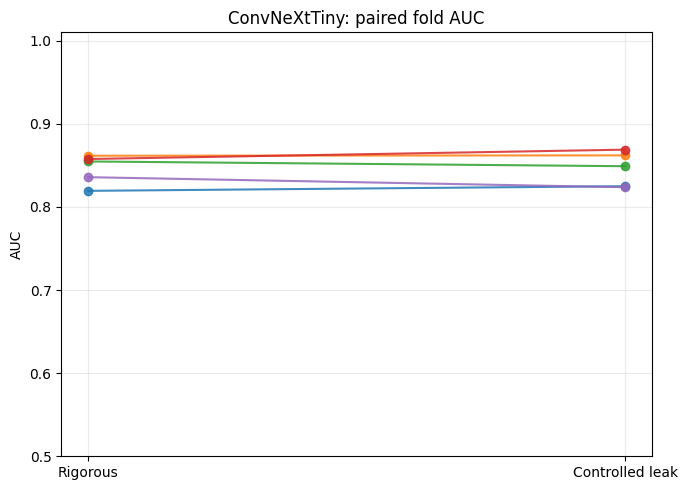

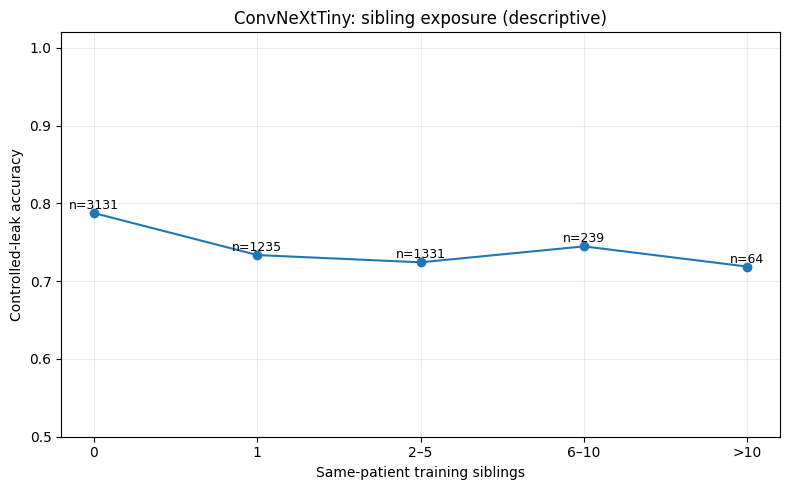

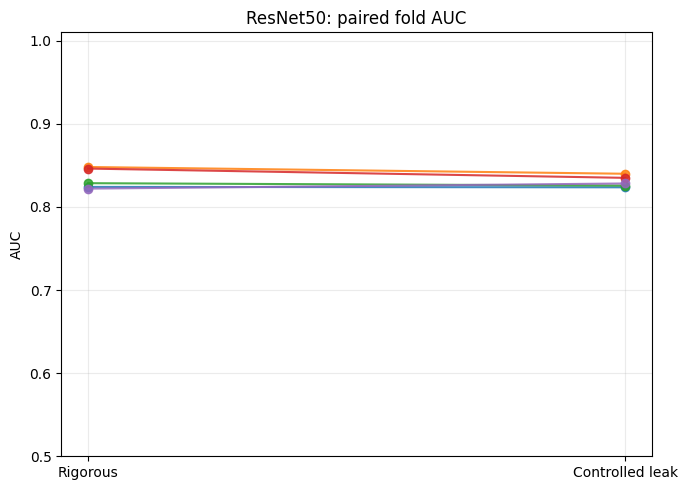

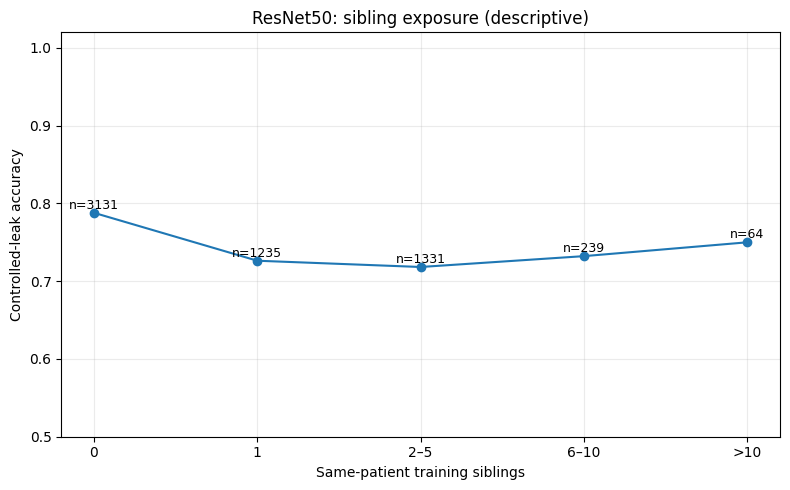

Figures saved -> /kaggle/working/nih_corrected_leakage_audit/figures


In [12]:
# =========================
# 12. Diagnostic figures
# =========================
import matplotlib.pyplot as plt

for arch, d in oof.groupby("architecture"):
    frows = []
    for fold, g in d.groupby("fold"):
        frows.append((
            fold,
            metric_from_arrays(g.Label, g.prob_rig, "AUC"),
            metric_from_arrays(g.Label, g.prob_leak, "AUC"),
        ))

    ff = pd.DataFrame(frows, columns=["fold", "rig", "leak"])

    fig, ax = plt.subplots(figsize=(7, 5))
    for _, r in ff.iterrows():
        ax.plot(["Rigorous", "Controlled leak"], [r.rig, r.leak], marker="o", alpha=0.85)
    ax.set_ylabel("AUC")
    ax.set_title(f"{arch}: paired fold AUC")
    ax.set_ylim(0.5, 1.01)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{arch}_paired_fold_auc.png", dpi=250, bbox_inches="tight")
    plt.show()

    z = d.copy()
    z["correct"] = (z.pred_leak == z.Label).astype(int)
    z["bucket"] = pd.cut(
        z.n_train_siblings,
        bins=[-0.1, 0.5, 1.5, 5.5, 10.5, np.inf],
        labels=["0", "1", "2–5", "6–10", ">10"]
    )

    b = z.groupby("bucket", observed=False).agg(
        n=("correct", "size"),
        n_patients=("Patient_ID", "nunique"),
        accuracy=("correct", "mean")
    ).reset_index()

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(b.bucket.astype(str), b.accuracy, marker="o")
    for i, r in b.iterrows():
        if np.isfinite(r.accuracy):
            ax.text(i, r.accuracy + 0.005, f"n={int(r.n)}", ha="center", fontsize=9)
    ax.set_xlabel("Same-patient training siblings")
    ax.set_ylabel("Controlled-leak accuracy")
    ax.set_title(f"{arch}: sibling exposure (descriptive)")
    ax.set_ylim(0.5, 1.02)
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{arch}_sibling_exposure.png", dpi=250, bbox_inches="tight")
    plt.show()

print("Figures saved ->", FIG_DIR)

In [13]:
# =========================
# 13. Automatic integrity report + manuscript-ready primary result table
# =========================
summary = {
    "dataset": "NIH ChestX-ray14",
    "target": TARGET,
    "task_definition": "Effusion present vs Effusion absent (one-vs-rest)",
    "primary_cohort_images": int(len(cohort)),
    "primary_cohort_patients": int(cohort.Patient_ID.nunique()),
    "primary_positive_prevalence": float(cohort.Label.mean()),
    "full_usable_metadata_positive_prevalence": float(meta.Label.mean()),
    "folds": int(FOLDS),
    "architectures": RUN_ARCHITECTURES,
    "decoded_content_duplicates_remaining_primary": int(cohort.duplicated("decoded_fp").sum()),
    "all_exact_row_overlap_zero": bool(
        (
            audit_df.rig_train_test_exact_row_overlap.eq(0)
            & audit_df.leak_train_test_exact_row_overlap.eq(0)
        ).all()
    ),
    "all_rawhash_overlap_zero": bool(
        (
            audit_df.rig_train_test_rawhash_overlap.eq(0)
            & audit_df.leak_train_test_rawhash_overlap.eq(0)
        ).all()
    ),
    "all_decoded_content_overlap_zero": bool(
        (
            audit_df.rig_train_test_decoded_overlap.eq(0)
            & audit_df.leak_train_test_decoded_overlap.eq(0)
        ).all()
    ),
    "all_rigorous_patient_overlap_zero": bool(
        audit_df.rig_train_test_patient_overlap.eq(0).all()
    ),
    "all_validation_test_patient_overlap_zero": bool(
        audit_df.val_test_patient_overlap.eq(0).all()
    ),
    "all_train_sizes_matched": bool(
        audit_df.rig_train_n.eq(audit_df.leak_train_n).all()
    ),
    "all_train_class_counts_matched": bool(
        (
            audit_df.rig_class0.eq(audit_df.leak_class0)
            & audit_df.rig_class1.eq(audit_df.leak_class1)
        ).all()
    ),
    "mean_test_sibling_exposure_pct": float(100 * audit_df.test_exposure_pct.mean()),
    "mean_same_label_sibling_exposure_pct": float(
        100 * audit_df.test_same_label_exposure_pct.mean()
    ),
    "mean_opposite_label_sibling_exposure_pct": float(
        100 * audit_df.test_opposite_label_exposure_pct.mean()
    ),
    "mean_same_view_sibling_exposure_pct": float(
        100 * audit_df.test_same_view_exposure_pct.mean()
    ),
    "patients_with_both_effusion_states": int(
        label_audit.patients_with_both_effusion_states.iloc[0]
    ),
    "native_prevalence_sensitivity_run": bool(RUN_NATIVE_PREVALENCE_SENSITIVITY),
}

with open(OUT / "integrity_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\n=== INTEGRITY SUMMARY ===")
print(json.dumps(summary, indent=2))

assert summary["decoded_content_duplicates_remaining_primary"] == 0
assert summary["all_exact_row_overlap_zero"]
assert summary["all_rawhash_overlap_zero"]
assert summary["all_decoded_content_overlap_zero"]
assert summary["all_rigorous_patient_overlap_zero"]
assert summary["all_validation_test_patient_overlap_zero"]
assert summary["all_train_sizes_matched"]
assert summary["all_train_class_counts_matched"]

primary = stats[
    stats.Metric.isin(["AUC", "PR_AUC", "Macro_F1", "ACC", "Brier"])
].copy()
primary.to_csv(OUT / "manuscript_primary_result_table.csv", index=False)

print("\n=== MANUSCRIPT-READY PRIMARY TABLE ===")
print(
    primary[[
        "Architecture", "Metric", "Rigorous", "ControlledLeak",
        "Delta_LeakMinusRig", "Delta_CI_Lo", "Delta_CI_Hi",
        "ClusterRandomization_p"
    ]].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\nInterpretation rules:")
print("- Call the exposure 'same-patient overlap' or 'same-patient training exposure'.")
print("- Never report the old random-KFold result as evidence from this corrected experiment.")
print("- If a delta CI crosses 0, report the effect as uncertain under the corrected design.")
print("- Sibling-count trends are associations, not a causal dose-response.")
print("- The prevalence extension is a native-prevalence-matched sample, not the full native dataset.")
print("- Brier/LogLoss are probabilistic scoring rules; do not call them calibration proof by themselves.")


=== INTEGRITY SUMMARY ===
{
  "dataset": "NIH ChestX-ray14",
  "target": "Effusion",
  "task_definition": "Effusion present vs Effusion absent (one-vs-rest)",
  "primary_cohort_images": 6000,
  "primary_cohort_patients": 3911,
  "primary_positive_prevalence": 0.5,
  "full_usable_metadata_positive_prevalence": 0.11877452729218695,
  "folds": 5,
  "architectures": [
    "ResNet50",
    "ConvNeXtTiny"
  ],
  "decoded_content_duplicates_remaining_primary": 0,
  "all_exact_row_overlap_zero": true,
  "all_rawhash_overlap_zero": true,
  "all_decoded_content_overlap_zero": true,
  "all_rigorous_patient_overlap_zero": true,
  "all_validation_test_patient_overlap_zero": true,
  "all_train_sizes_matched": true,
  "all_train_class_counts_matched": true,
  "mean_test_sibling_exposure_pct": 47.81666666666668,
  "mean_same_label_sibling_exposure_pct": 38.08333333333333,
  "mean_opposite_label_sibling_exposure_pct": 24.250000000000004,
  "mean_same_view_sibling_exposure_pct": 38.916666666666664,
  "p

In [14]:
# =========================
# 14. Bundle the complete reproducibility package
# =========================
readme = f"""NIH CHESTX-RAY14 CORRECTED SAME-PATIENT LEAKAGE AUDIT

Primary cohort
- target: {TARGET}
- task: Effusion present vs Effusion absent (one-vs-rest)
- images: {len(cohort)}
- patients: {cohort.Patient_ID.nunique()}
- positive prevalence: {cohort.Label.mean():.6f}
- architectures: {", ".join(RUN_ARCHITECTURES)}
- folds: {FOLDS}

Design
- Fixed test images per fold.
- Rigorous arm: zero test-patient overlap with training.
- Controlled-leak arm: exact/duplicate test images remain forbidden, while other
  radiographs from some test patients are deliberately introduced.
- Training size and binary class counts are matched by same-class swaps.
- Both arms use the identical safe patient-disjoint validation set.
- Test data are not used for early stopping.
- Paired uncertainty uses patient-cluster bootstrap and patient-cluster randomization.
- Same-label, opposite-label, and same-view sibling exposure are reported separately.
- Negative class means Effusion absent; it is not assumed to mean No Finding.

Key outputs
- primary_cohort_manifest.csv
- primary_negative_class_composition.csv
- primary_patient_structure.csv
- primary_leakage_audit_by_fold.csv
- primary_oof_paired_predictions.csv
- primary_cluster_aware_metrics.csv
- primary_patient_label_concordance.csv
- primary_leakage_exposure_groups.csv
- primary_leakage_exposure_trends.csv
- manuscript_primary_result_table.csv
- integrity_summary.json
- splits/
- predictions/
- figures/

Native-prevalence sensitivity
- enabled: {RUN_NATIVE_PREVALENCE_SENSITIVITY}
- sample n: {NATIVE_SENSITIVITY_N}
- prevalence is matched to the prevalence measured from the attached usable NIH metadata.
- this is a sensitivity sample, not the full native dataset.

Software
{json.dumps(versions, indent=2)}
"""

(OUT / "README.txt").write_text(readme)

archive = BASE / "NIH_Corrected_Leakage_Audit_Results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(BASE))

print("Results archive:", archive)
print("Notebook run complete.")

Results archive: /kaggle/working/NIH_Corrected_Leakage_Audit_Results.zip
Notebook run complete.
